# Case Study: Testing Covasim with Confounded Observational Data

This tutorial walks through the fourth case study (Section 5.4) of our paper
[*Testing Causality in Scientific Modelling Software*](https://dl.acm.org/doi/10.1145/3607184).
We use the Causal Testing Framework (CTF) to predict how the transmissibility of COVID-19 affects the number of
infections in [Covasim](https://github.com/InstituteforDiseaseModeling/covasim), for each of the 156 locations it
can simulate.

In the [previous case study](covasim_vaccinating_elderly.ipynb) we used data where the only difference between
two groups of Covasim runs was the input we were interested in. Here we do something much harder: we infer the outcomes of 156 metamorphic tests from **observational
data**. This is data that wasn't designed for our tests, and which is **confounded**, so a naive analysis gives the
wrong answer. We'll see how causal knowledge lets us get the right answer anyway, with a fraction of the model runs
that conventional statistical metamorphic testing would need.

By the end of this tutorial you will have:

1. seen how confounding can mislead a naive statistical analysis;
2. used a **causal DAG** to find valid **adjustment sets** and chosen between them;
3. built a regression model that combines causal knowledge with domain expertise;
4. run 156 **causal test cases**, one per location, and compared them against a "gold standard";
5. investigated **how much data** the CTF actually needs.

You only need basic familiarity with Python and pandas. We'll explain the statistical and causal ideas as we go.

## Background: the testing problem

Covasim is an agent-based COVID-19 simulator. It simulates a population of individual people who live in households,
attend schools and workplaces, and pass the virus between them through their contacts.

One of Covasim's inputs is $\beta$ (`beta`), the **transmissibility** of the virus, i.e. how likely it is to spread
during a contact. Different variants of COVID-19 have different values of $\beta$:

| Variant | $\beta$ |
|---|---|
| Beta | 0.016 |
| Alpha | 0.02672 |
| Gamma | 0.0328 |
| Delta | 0.0352 |

We want to test the following metamorphic relation:

> **MR:** Increasing $\beta$ from 0.016 (the Beta variant) to 0.02672 (the Alpha variant) should increase the
> cumulative number of infections.

That much is obvious. The interesting question is **by how much**. Covasim can simulate 156 different locations
(countries and regions), each with its own population structure, such as age distribution and household size. These
affect how the virus spreads, so the effect of changing $\beta$ is different in each location. That gives us **156
metamorphic relations**, one per location.

Testing these with conventional statistical metamorphic testing (SMT) is expensive. We'd need to run Covasim, say,
30 times with each value of $\beta$ in each location. That's $30 \times 2 \times 156 = 9360$ runs, each of which
takes a minute or two.

## The causal testing workflow

As in the other tutorials, we follow these steps:

1. **Specify the scenario and causal DAG**, i.e. our assumptions about cause and effect.
2. **Collect data**, i.e. runs of the system under test.
3. **Define causal test cases** that say which input we change, how we change it, and what we expect to happen.
4. **Identification:** use the DAG to work out what we must adjust for to avoid confounding.
5. **Estimation:** fit a statistical model to estimate each causal effect.
6. **Apply the test oracle:** compare the estimates against our expectations.

## Step 1: The modelling scenario and causal DAG

### Modelling scenario

We use the default Covasim parameters, except for `beta` and `location`, which vary between runs. We also fix the
simulation length to 200 days, the population size to 1 million people, and the number of initially infected people
to 1000:

$$\{\text{days} = 200,\ \text{pop\_size} = 1000000,\ \text{pop\_infected} = 1000\}$$

### Causal DAG

The causal DAG records our assumptions about how Covasim works. An arrow $X \rightarrow Y$ means "$X$ directly affects
$Y$", and a *missing* arrow means that it doesn't. The DAG for this case study is included with the CTF.

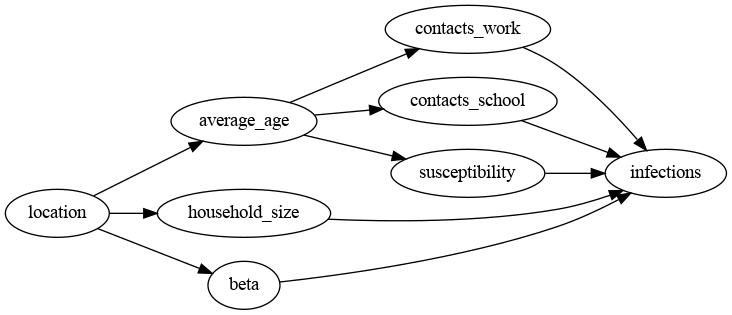

In [1]:
from causal_testing.examples.covasim import disease_variants as dv
from causal_testing.specification.causal_dag import CausalDAG

from tutorial_utils import render_dag


dag = CausalDAG(dv.dag_path)
render_dag(dag)

Here's what each node means, and why the arrows are there:

| Node | Meaning |
|---|---|
| `location` | the country or region being simulated |
| `average_age` | the average age of the population |
| `household_size` | the average number of household contacts per person |
| `contacts_school`, `contacts_work` | school and workplace contacts |
| `susceptibility` | how susceptible the population is to infection, on average |
| `beta` | the transmissibility of the virus |
| `infections` | the cumulative number of infections at the end of the simulation |

* **`location` → `average_age`, `household_size`**. Each location has its own age distribution and household
  structure.
* **`average_age` → `contacts_school`, `contacts_work`, `susceptibility`**. Age determines whether someone goes to
  school or work, and older people are more susceptible to infection.
* **`household_size`, `contacts_school`, `contacts_work`, `susceptibility` → `infections`**. More contacts and more
  susceptible people mean more infections.
* **`beta` → `infections`**. This is the effect we want to measure.
* **`location` → `beta`**. This is the important one. In our data, each location has its own *dominant variant*, and
  hence its own range of $\beta$ values. We'll see why this is a problem shortly.

## Step 2: The data

### Observational data

To simulate the kind of "messy" data you might already have lying around, each of the 156 locations was randomly
assigned a dominant variant (Alpha, Beta, Gamma, or Delta). Covasim was then run 30 times per location, with $\beta$
drawn each time from a normal distribution centred on that variant's $\beta$ (with a standard deviation of 0.002).
That gives $30 \times 156 = 4680$ runs, half the number needed for conventional SMT.

In [2]:
import numpy as np
import pandas as pd

df = dv.df
df

,location,average_age,beta,household_size,contacts_school,contacts_work,total_contacts_school,total_contacts_work,susceptibility,infections
0,mongolia,29.401,0.01465,3.443,20.014,16.000,2731228,4346312,0.824225,791634
1,mongolia,29.420,0.01561,3.452,20.012,15.998,2733810,4347048,0.824736,811405
2,mongolia,29.393,0.01575,3.449,19.975,16.001,2731258,4346197,0.824350,814960
3,mongolia,29.391,0.01698,3.448,20.006,15.997,2729426,4346684,0.824276,834737
4,mongolia,29.395,0.01876,3.440,20.001,16.003,2732380,4341776,0.824137,858812
...,...,...,...,...,...,...,...,...,...,...
4675,greece,45.217,0.02324,1.883,20.004,16.001,1567581,4527337,1.017668,908808
4676,greece,45.182,0.02644,1.887,19.995,15.988,1570539,4514028,1.017216,928411
4677,greece,45.224,0.02358,1.887,20.009,16.005,1569078,4516831,1.017661,911786
4678,greece,45.279,0.02685,1.887,20.001,16.002,1563737,4519090,1.018352,931457


Each row is one run of Covasim. Let's see how $\beta$ varies across the data, colouring each location by its assigned
variant:

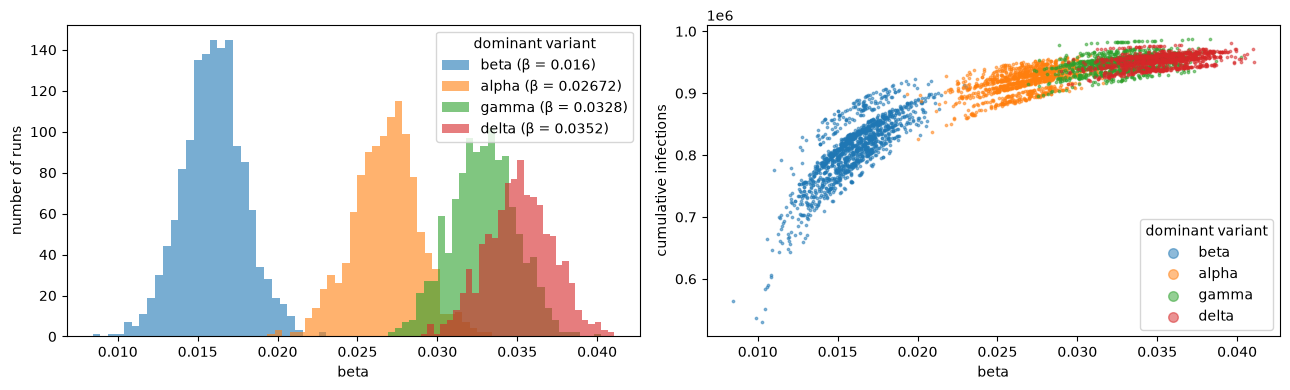

In [3]:
import matplotlib.pyplot as plt

# Recover each location's dominant variant from the beta value its runs are centred on
location_beta = df.groupby("location")["beta"].mean()
variant_of_location = location_beta.apply(
    lambda b: min(dv.variant_betas, key=lambda variant: abs(dv.variant_betas[variant] - b))
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for variant, variant_beta in sorted(dv.variant_betas.items(), key=lambda item: item[1]):
    runs = df[df["location"].map(variant_of_location) == variant]
    axes[0].hist(runs["beta"], bins=30, alpha=0.6, label=f"{variant} (β = {variant_beta})")
    axes[1].scatter(runs["beta"], runs["infections"], s=3, alpha=0.5, label=variant)
axes[0].set_xlabel("beta")
axes[0].set_ylabel("number of runs")
axes[0].legend(title="dominant variant")
axes[1].set_xlabel("beta")
axes[1].set_ylabel("cumulative infections")
axes[1].legend(title="dominant variant", markerscale=4)
plt.tight_layout()
plt.show()

Two things stand out:

1. **No location has been run with both $\beta$ values we're interested in.** Locations with the Beta variant only have
   $\beta$ values around 0.016, and locations with the Alpha variant only have values around 0.02672. So we can't just
   compare runs within a location, as we would in conventional SMT.
2. **There's lots of variation in infections for any given $\beta$.** Some of it is down to random chance, but much of
   it is because different locations have different populations.

This is **confounding**. `location` affects both the treatment (`beta`, through the dominant variant) and the outcome
(`infections`, through the population structure). If, by chance, the Alpha variant had been assigned to locations
where the virus spreads easily anyway, a naive comparison would overestimate the effect of $\beta$.

### The "gold standard"

To check how well the CTF does, we also have the results of conventional SMT. Here, Covasim was run 30 times with
$\beta = 0.016$ and 30 times with $\beta = 0.02672$ in *every* location, i.e. 9360 runs. These runs are included with
the CTF as `dv.smt_df`.

In [4]:
smt_df = dv.smt_df
smt_df

,location,beta,infections
0,cyprus,0.01600,819195
1,cyprus,0.01600,819940
2,cyprus,0.01600,819389
3,cyprus,0.01600,818901
4,cyprus,0.01600,819019
...,...,...,...
9355,estonia,0.02672,918942
9356,estonia,0.02672,918737
9357,estonia,0.02672,918848
9358,estonia,0.02672,919206


For each location, the gold standard effect is simply the average number of infections with $\beta = 0.02672$ minus
the average with $\beta = 0.016$:

In [5]:
control_beta, treatment_beta = dv.variant_betas["beta"], dv.variant_betas["alpha"]

smt_means = smt_df.groupby(["location", "beta"])["infections"].mean().unstack()
gold_standard = (smt_means[treatment_beta] - smt_means[control_beta]).rename("gold_standard")
gold_standard.sort_values()

location
oman                      46236.500000
maldives                  65794.700000
senegal                   71730.033333
iraq                      72743.933333
afghanistan               75353.366667
                             ...      
france                   131848.733333
uganda                   132475.533333
ghana                    132825.500000
finland                  134063.733333
sao tome and principe    135211.800000
Name: gold_standard, Length: 156, dtype: float64

The effect ranges from about 46,000 extra infections (Oman) to about 135,000 (São Tomé and Príncipe), so location
really does matter.

Our goal is to reproduce these 156 numbers using only the 4680 observational runs.

## Step 3: Defining the causal test cases

We define one causal test case per location. Each one estimates the **average treatment effect** (ATE) of increasing
$\beta$ from 0.016 to 0.02672 on cumulative infections, *in that location*. Because the effect depends on the
characteristics of the location, this is sometimes called a *conditional* average treatment effect (CATE):

$$CATE = \mathbb{E}[I \mid \beta = 0.02672, \text{location}] - \mathbb{E}[I \mid \beta = 0.016, \text{location}]$$

We expect infections to increase in every location, so the expected effect for each test is `Positive()`. More
importantly, we'll compare the size of each estimated effect with the gold standard.

## Step 4: Identification

Now we need to deal with the confounding. Identification uses the DAG to find a set of variables that, if we adjust
for them, "block" every non-causal path between treatment and outcome. Such a set is called an **adjustment set**.

Here, the problematic paths go `beta` ← `location` → ... → `infections`. Any set of variables that cuts all of these
paths will do. The CTF can list all the *minimal* adjustment sets, i.e. those that contain no unnecessary variables:

In [6]:
list(dag.enumerate_minimal_adjustment_sets(["beta"], ["infections"]))

[{'contacts_school', 'contacts_work', 'household_size', 'susceptibility'},
 {'average_age', 'household_size'},
 {'location'}]

There are three options. All of them are valid, meaning they all remove the confounding in theory. But they're not
equally useful in practice.

1. **`{location}`**. This is the smallest set. However, adjusting for location means we can only learn about each
   location from its own runs. As we saw above, each location only has 30 runs, all with a narrow range of $\beta$
   values. To predict what would happen at the other $\beta$ value, the model would have to extrapolate a long way.
2. **`{average_age, household_size}`**. This lets us "borrow" information from locations with similar average ages and
   household sizes. But the average age is a poor summary of a population. Two locations with the same average age
   can have very different age distributions, and it's the distribution that determines how many people go to school
   or work, and how susceptible they are.
3. **`{susceptibility, contacts_school, contacts_work, household_size}`**. This replaces average age with the
   things that age actually affects, and which in turn affect infections directly. It still lets us borrow
   information from similar locations, but describes "similar" more precisely.

Following the paper, we use the **third adjustment set**. This shows an important practical point: identification
tells you *which* adjustment sets are valid, but domain knowledge helps you choose the *best* one.

### Measuring school and workplace contacts

There's one subtlety with the third adjustment set. Covasim gives each person who attends school or work roughly the
same number of contacts there (about 20 and 16 respectively), whatever the location. So the per-person averages in the
`contacts_school` and `contacts_work` columns hardly vary at all:

In [7]:
df[["contacts_school", "contacts_work", "total_contacts_school", "total_contacts_work"]].describe().round(3)

,contacts_school,contacts_work,total_contacts_school,total_contacts_work
count,4680.000,4680.000,4680.000,4680.000
mean,20.000,16.000,2712511.674,4120733.191
std,0.009,0.006,873492.959,616640.081
min,19.962,15.976,1395069.000,2681747.000
25%,19.994,15.996,1876342.750,3547506.500
50%,20.000,16.000,2706642.000,4304195.500
75%,20.006,16.004,3593012.750,4600861.750
max,20.041,16.019,4200472.000,5314108.000


What *does* vary between locations is how many people go to school or work in the first place, and that depends on
the population's age distribution. The `total_contacts_school` and `total_contacts_work` columns capture this, so we
use them to measure school and workplace contacts in our model.

## Step 5: Estimation

Now we need a regression model that includes $\beta$ and our adjustment set. Writing $Z$ for the adjustment set
$\{S, C_S, C_W, C_H\}$ (susceptibility, school, work, and household contacts), we use:

$$I \sim \beta_0 + \beta_1 \ln(\beta) + \beta_2 \ln(\beta)^2 + \sum_{z \in Z} \left( \beta_{z1} \ln(z) + \beta_{z2} \ln(z)^2 + \beta_{z3} \ln(z) \ln(\beta) \right)$$

This looks complicated, but each part encodes a simple assumption:

1. **Logarithms**. Viral infection spreads exponentially, so we take the logarithm of $\beta$ and of each adjustment
   variable.
2. **Squared terms**. These let the model capture curved (rather than straight-line) relationships between each
   variable and infections.
3. **Interaction terms** $\ln(z)\ln(\beta)$. We expect the *effect* of $\beta$ to depend on the population. For
   example, a more transmissible variant should cause more extra infections in a population with lots of contacts.
   These terms let the model make a different estimate for each location.

We came up with these assumptions by varying each parameter in isolation and watching what happened to infections. An
epidemiologist may well be able to suggest better ones.

To put this model into practice, we first add log-transformed columns to the data:

In [8]:
adjustment_set = ["susceptibility", "total_contacts_school", "total_contacts_work", "household_size"]

log_df = df.copy()
for variable in ["beta"] + adjustment_set:
    log_df[f"log_{variable}"] = np.log(log_df[variable])

terms = ["log_beta", "I(log_beta ** 2)"]
for z in adjustment_set:
    terms += [f"log_{z}", f"I(log_{z} ** 2)", f"log_beta:log_{z}"]
formula = "infections ~ " + " + ".join(terms)
print(formula)

infections ~ log_beta + I(log_beta ** 2) + log_susceptibility + I(log_susceptibility ** 2) + log_beta:log_susceptibility + log_total_contacts_school + I(log_total_contacts_school ** 2) + log_beta:log_total_contacts_school + log_total_contacts_work + I(log_total_contacts_work ** 2) + log_beta:log_total_contacts_work + log_household_size + I(log_household_size ** 2) + log_beta:log_household_size


In this formula, `I(x ** 2)` means "the square of $x$" and `a:b` means "the product of $a$ and $b$".

To estimate the effect for a particular location, we fix each adjustment variable at its average value for that
location. We do this with the estimator's `adjustment_config` argument. Because our treatment variable is now
`log_beta`, the control and treatment values are $\ln(0.016)$ and $\ln(0.02672)$.

## Step 6: Running the tests

We now run one causal test case per location. This takes a few seconds, since it fits 156 regression models.

In [9]:
from causal_testing.estimation.linear_regression_estimator import LinearRegressionEstimator
from causal_testing.testing.causal_effect import Positive
from causal_testing.testing.causal_test_case import CausalTestCase

log_adjustment_set = [f"log_{z}" for z in adjustment_set]


def ctf_estimates(data: pd.DataFrame, location_profiles: pd.DataFrame) -> pd.DataFrame:
    # Run one causal test per location, fitting the model to `data` and describing each location by
    # its average (log-transformed) adjustment variables in `location_profiles`.
    results = []
    for location, profile in location_profiles.iterrows():
        estimator = LinearRegressionEstimator(
            treatment_variable="log_beta",
            outcome_variable="infections",
            control_value=np.log(control_beta),
            treatment_value=np.log(treatment_beta),
            formula=formula,
            adjustment_config=profile.to_dict(),
            alpha=0.05,
        )
        test_case = CausalTestCase(
            expected_causal_effect=Positive(),
            effect_measure="ate_calculated",  # Predict infections under control and treatment, then subtract
            estimator=estimator,
        )
        test_case.execute_test(data)
        estimate = test_case.result.effect_estimate
        results.append(
            {
                "location": location,
                "ctf_estimate": estimate.effect_estimate.iloc[0],
                "ci_low": estimate.ci_low.iloc[0],
                "ci_high": estimate.ci_high.iloc[0],
                "outcome": test_case.result.outcome.name,
            }
        )
    return pd.DataFrame(results).set_index("location")


location_profiles = log_df.groupby("location")[log_adjustment_set].mean()
ctf_results = ctf_estimates(log_df, location_profiles)
ctf_results = ctf_results.join(gold_standard)
ctf_results

,ctf_estimate,ci_low,ci_high,outcome,gold_standard
location,,,,,
afghanistan,83675.731942,82298.564777,85052.899106,PASS,75353.366667
albania,106720.148835,105847.204533,107593.093137,PASS,99700.200000
angola,133723.107686,132649.676646,134796.538726,PASS,128868.266667
argentina,119267.027324,118461.555434,120072.499214,PASS,113817.166667
armenia,104344.347646,103594.423828,105094.271463,PASS,99477.600000
...,...,...,...,...,...
venezuela,101820.463568,101062.264639,102578.662498,PASS,95677.466667
vietnam,103485.565990,102761.797081,104209.334898,PASS,98059.066667
yemen,91091.232331,90223.444814,91959.019847,PASS,85663.733333


First, the metamorphic relation itself. Increasing $\beta$ should increase infections in every location:

In [10]:
ctf_results["outcome"].value_counts()

outcome
PASS    156
Name: count, dtype: int64

All 156 tests pass. But we can go further and check whether the *size* of each estimate matches the gold standard.
We use two measures:

* **Root mean square percentage error (RMSPE)**. This is, roughly, the typical percentage error of each estimate. Lower
  is better, and 0 means perfect.
* **Kendall's rank correlation ($\tau$)**. This measures whether the CTF puts the locations in the same *order* as the
  gold standard, from smallest to largest effect. It ranges from −1 to 1, and 1 means the order is identical.

In [11]:
from scipy.stats import kendalltau


def rmspe(estimates, truth):
    return np.sqrt((((estimates - truth) / truth) ** 2).mean())


def evaluate(estimates):
    truth = gold_standard.loc[estimates.index]
    return pd.Series({"RMSPE": rmspe(estimates, truth), "Kendall's tau": kendalltau(estimates, truth).statistic})


evaluate(ctf_results["ctf_estimate"])

RMSPE            0.054780
Kendall's tau    0.944417
dtype: float64

The CTF estimates are typically within about 5.5% of the gold standard, and the ordering of locations is very well
preserved ($\tau \approx 0.94$).

### Comparison: a naive regression model

How much did the causal knowledge help? To find out, let's compare with a naive model that ignores the DAG and simply
regresses infections on $\beta$:

$$I \sim \beta_0 + \beta_1 \ln(\beta) + \beta_2 \ln(\beta)^2$$

This model has no location-specific information, so it makes the same prediction for every location.

In [12]:
naive_test = CausalTestCase(
    expected_causal_effect=Positive(),
    effect_measure="ate_calculated",
    estimator=LinearRegressionEstimator(
        treatment_variable="log_beta",
        outcome_variable="infections",
        control_value=np.log(control_beta),
        treatment_value=np.log(treatment_beta),
        formula="infections ~ log_beta + I(log_beta ** 2)",
    ),
)
naive_test.execute_test(log_df)
ctf_results["naive_estimate"] = naive_test.result.effect_estimate.effect_estimate.iloc[0]

evaluate(ctf_results["naive_estimate"])[["RMSPE"]]

RMSPE    0.200246
dtype: float64

The naive model is off by about 20% on average, nearly four times worse than the CTF. (We don't report Kendall's
$\tau$ here, because every location gets the same estimate, so there's no ordering to compare.)

The plot below reproduces Figure 8 of the paper. Locations are sorted by their gold standard effect.

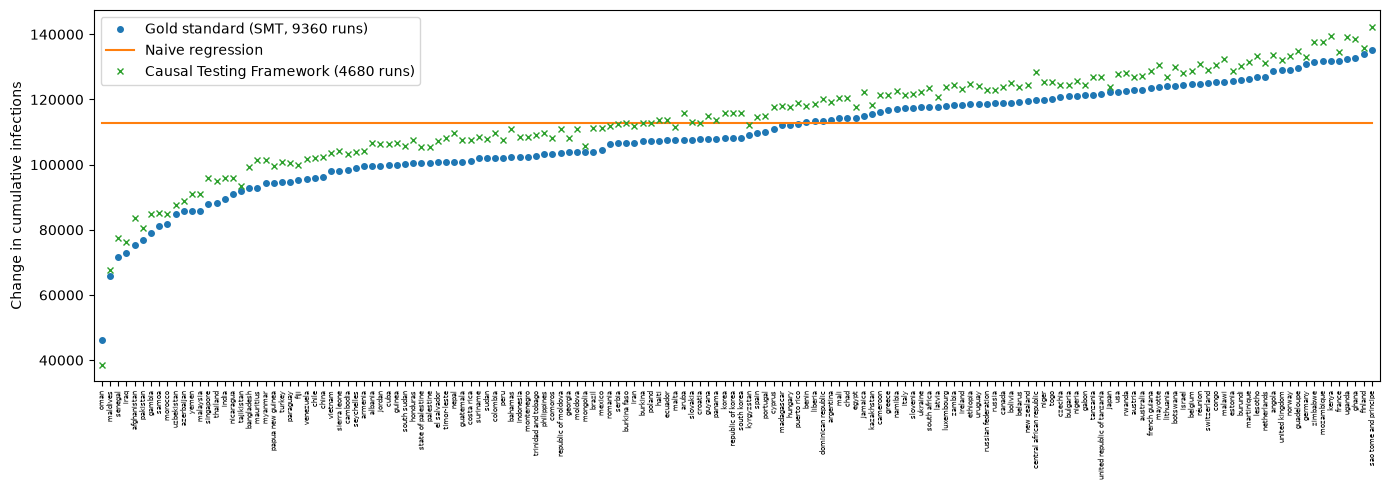

In [13]:
plot_df = ctf_results.sort_values("gold_standard")
x = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(x, plot_df["gold_standard"], "o", markersize=4, label="Gold standard (SMT, 9360 runs)")
ax.plot(x, plot_df["naive_estimate"], "-", label="Naive regression")
ax.plot(x, plot_df["ctf_estimate"], "x", markersize=4, label="Causal Testing Framework (4680 runs)")
ax.set_xticks(x, plot_df.index, rotation=90, fontsize=5)
ax.set_xlim(-1, len(plot_df))
ax.set_ylabel("Change in cumulative infections")
ax.legend()
plt.tight_layout()
plt.show()

The CTF estimates closely follow the gold standard across all locations, tending to slightly overestimate the effect.
The naive model is reasonable for "average" locations but badly wrong for locations at either extreme.

### Comparison: adjusting for location only

What if we'd used the smallest adjustment set, `{location}`? This means estimating the effect in each location using
mostly its own data. We can do this by letting the effect of $\beta$ vary by location with an interaction term. Here
`C(location)` tells the regression model to treat location as a category:

In [14]:
location_results = {}
for location in location_profiles.index:
    test_case = CausalTestCase(
        expected_causal_effect=Positive(),
        effect_measure="ate_calculated",
        estimator=LinearRegressionEstimator(
            treatment_variable="log_beta",
            outcome_variable="infections",
            control_value=np.log(control_beta),
            treatment_value=np.log(treatment_beta),
            formula="infections ~ log_beta + I(log_beta ** 2) + C(location) + log_beta:C(location)",
            adjustment_config={"location": location},
        ),
    )
    test_case.execute_test(log_df)
    location_results[location] = test_case.result.effect_estimate.effect_estimate.iloc[0]

ctf_results["location_estimate"] = pd.Series(location_results)
evaluate(ctf_results["location_estimate"])

RMSPE            0.514654
Kendall's tau    0.228122
dtype: float64

This is far worse than either other model, with an average error of over 50% and a poor ordering of locations. Each
location only has 30 runs, all with $\beta$ values close together, so the model has to extrapolate a long way to
predict what would happen with the other variant. This is essentially an attempt to do SMT on incomplete, confounded
data.

So the validity of an adjustment set isn't the whole story. Choosing a set that lets us borrow information across
locations, and describing "similar" locations in a way that matches how the virus actually spreads, makes all the
difference.

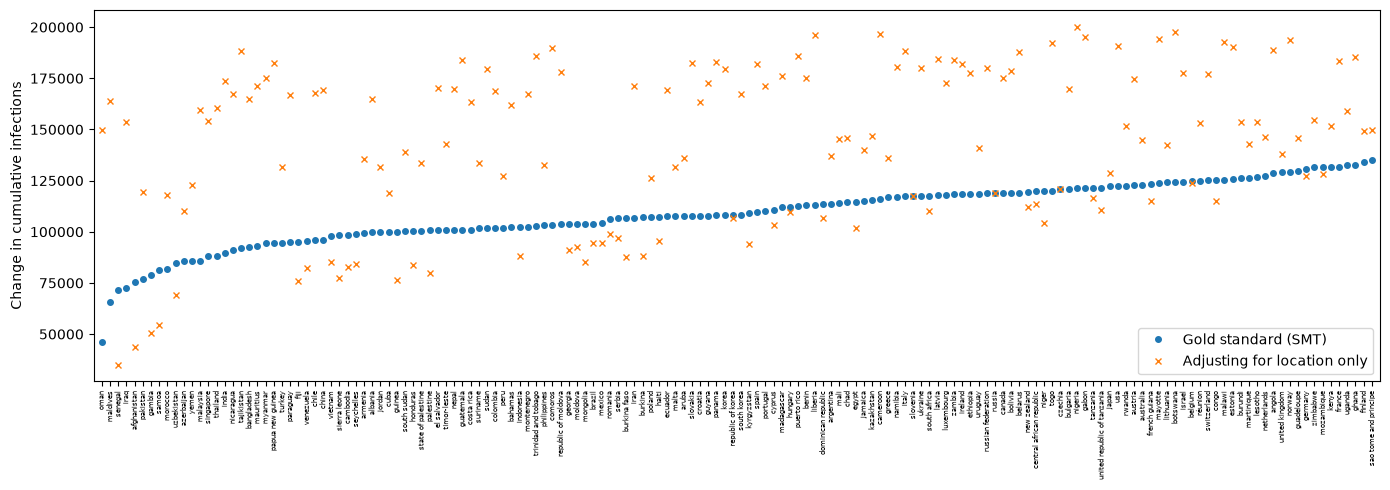

In [15]:
plot_df = ctf_results.sort_values("gold_standard")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(x, plot_df["gold_standard"], "o", markersize=4, label="Gold standard (SMT)")
ax.plot(x, plot_df["location_estimate"], "x", markersize=4, label="Adjusting for location only")
ax.set_xticks(x, plot_df.index, rotation=90, fontsize=5)
ax.set_xlim(-1, len(plot_df))
ax.set_ylabel("Change in cumulative infections")
ax.legend()
plt.tight_layout()
plt.show()

## How much data do we actually need?

So far we've used all 4680 observational runs. That's already half of what conventional SMT would need, but it's
still a lot. How much data does the CTF need to give good answers?

To find out, we take random samples of the observational data of increasing size, re-run all 156 causal tests on each
sample, and measure the RMSPE and Kendall's $\tau$ against the gold standard. We repeat this several times for each
sample size to see how much the results vary.

As in the original study, we still describe each location by its average characteristics in the full dataset (the
`location_profiles` from before). These describe the location's *population*, not the outcome we're predicting.

This takes a minute or two to run. The paper repeated each sample size 30 times. Here we use 5 repeats to save time,
but you can increase `n_repeats` to get smoother results.

In [16]:
sample_sizes = [25, 50, 100, 200, 500, 1000, 2000]
n_repeats = 5

subset_results = []
for size in sample_sizes:
    for seed in range(n_repeats):
        sample = log_df.sample(n=size, random_state=seed)
        estimates = ctf_estimates(sample, location_profiles)["ctf_estimate"]
        subset_results.append({"data_points": size, "seed": seed, **evaluate(estimates)})

subset_results = pd.DataFrame(subset_results)
subset_results.groupby("data_points")[["RMSPE", "Kendall's tau"]].agg(["mean", "min", "max"]).round(3)

RMSPE               Kendall's tau              
              mean    min    max          mean    min    max
data_points                                                 
25           0.089  0.057  0.120         0.738  0.548  0.866
50           0.070  0.047  0.135         0.832  0.554  0.947
100          0.058  0.034  0.119         0.918  0.882  0.941
200          0.051  0.032  0.084         0.914  0.897  0.927
500          0.050  0.038  0.071         0.934  0.910  0.943
1000         0.054  0.046  0.063         0.942  0.933  0.949
2000         0.055  0.048  0.059         0.944  0.935  0.949

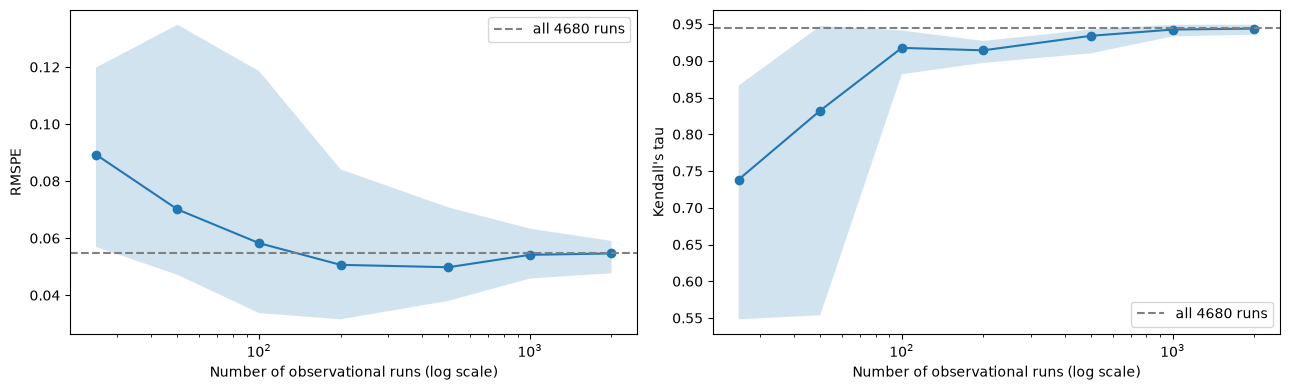

In [17]:
summary = subset_results.groupby("data_points")[["RMSPE", "Kendall's tau"]].agg(["mean", "min", "max"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["RMSPE", "Kendall's tau"]):
    ax.plot(summary.index, summary[(metric, "mean")], "o-")
    ax.fill_between(summary.index, summary[(metric, "min")], summary[(metric, "max")], alpha=0.2)
    ax.axhline(evaluate(ctf_results["ctf_estimate"])[metric], color="grey", linestyle="--", label="all 4680 runs")
    ax.set_xscale("log")
    ax.set_xlabel("Number of observational runs (log scale)")
    ax.set_ylabel(metric)
    ax.legend()
plt.tight_layout()
plt.show()

With only a few dozen runs, the estimates are noticeably less accurate and vary a lot depending on which runs we happen
to sample. By around **200 runs**, however, the CTF is about as accurate as it is with all 4680. Beyond that, extra data makes very little difference. Compare that with the 9360 runs needed for
conventional SMT.

## Summary

In this tutorial we used the CTF to infer the outcomes of 156 metamorphic tests on Covasim from **confounded
observational data**:

1. We saw that a naive analysis is misleading, because `location` affects both $\beta$ and the number of infections.
2. We used the **causal DAG** to find three valid adjustment sets, and used domain knowledge to choose the one that
   best captures *why* locations differ.
3. We built a **regression model** using logarithms, squared terms, and interactions to reflect how the virus spreads.
4. The CTF's estimates were within about 5.5% of the gold standard and ordered the locations almost perfectly. A naive
   model and a model adjusting only for location did much worse.
5. The CTF needed only around **200 runs** to reach this accuracy, compared with 9360 for conventional SMT.

The CTF does ask more of the tester than conventional SMT. We needed a causal DAG and some understanding of the
*shape* of the relationships between variables. But in return, we could reuse data that was never designed for our
tests and answer 156 questions at once, with a small fraction of the model runs.

## Further resources

* [Testing Causality in Scientific Modelling Software (paper)](https://dl.acm.org/doi/10.1145/3607184)
* [Original code and data for this case study](https://github.com/AndrewC19/covasim_case_study/tree/65bc40a)
* [Covasim on GitHub](https://github.com/InstituteforDiseaseModeling/covasim)
* [Causal Testing Framework on GitHub](https://github.com/CITCOM-project/CausalTestingFramework)
* [Causal Testing Framework documentation](https://causal-testing-framework.readthedocs.io/en/latest/index.html)